<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js15/TG15_1_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **JS15 - Pipeline Machine Learning & Deployment**

## Langkah 1: Install & Import Library

In [1]:
!pip install -q "kagglehub[pandas-datasets]"

In [2]:
import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub
from kagglehub import KaggleDatasetAdapter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Langkah 2: Load Dataset dari Kaggle


In [3]:
DATASET = "abiyyurasyiq/jakarta-house-price-dataset"

# 1) Unduh dataset & cari file CSV
dataset_dir = kagglehub.dataset_download(DATASET)
csv_files = []
for root, _, files in os.walk(dataset_dir):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_files.append(os.path.relpath(os.path.join(root, f), dataset_dir))
print("File CSV ditemukan:", csv_files)

# 2) Load file CSV pertama dengan kagglehub (sesuai snippet dari Kaggle)
file_path = csv_files[0]
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    DATASET,
    file_path,
)

print("Ukuran data:", df.shape)
print("First 5 records:")
df.head()

Using Colab cache for faster access to the 'jakarta-house-price-dataset' dataset.
File CSV ditemukan: ['jakarta_house.csv']


/tmp/ipykernel_865/4012619822.py:14: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'jakarta-house-price-dataset' dataset.
Ukuran data: (10000, 9)
First 5 records:


,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


## Langkah 3: Eksplorasi Data (EDA)


In [4]:
# Rapikan nama kolom agar konsisten
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())
df.info()

['index', 'price', 'district', 'city', 'bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB


In [5]:
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.drop(columns=["index"], errors="ignore").duplicated().sum())
df.describe().T

Missing value per kolom:
index            0
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        3
building_area    5
dtype: int64

Jumlah baris duplikat: 526


,count,mean,std,min,25%,50%,75%,max
index,10000.0,5.000500e+03,2.886896e+03,1.0,2.500750e+03,5.000500e+03,7.500250e+03,1.000000e+04
price,10000.0,1.004029e+10,2.004519e+10,1850000.0,2.500000e+09,4.500000e+09,9.800000e+09,9.000000e+11
bed_rooms,10000.0,4.253500e+00,3.176609e+00,0.0,3.000000e+00,4.000000e+00,5.000000e+00,6.300000e+01
bath_rooms,10000.0,3.521300e+00,2.900136e+00,0.0,2.000000e+00,3.000000e+00,4.000000e+00,6.300000e+01
carport,10000.0,1.578900e+00,1.743467e+00,0.0,1.000000e+00,1.000000e+00,2.000000e+00,3.100000e+01
land_area,9997.0,2.966102e+02,5.029217e+02,1.0,1.000000e+02,1.770000e+02,3.350000e+02,1.771400e+04
building_area,9995.0,3.199625e+02,3.576760e+02,1.0,1.390000e+02,2.300000e+02,4.000000e+02,1.533100e+04


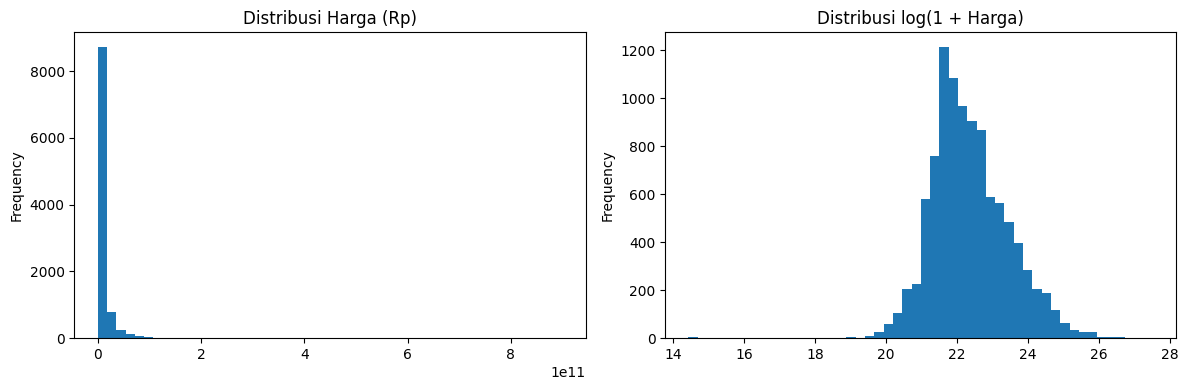

Jumlah kota    : 5
Jumlah district: 253


,count
city,
Jakarta Selatan,3379
Jakarta Barat,2622
Jakarta Utara,1739
Jakarta Timur,1690
Jakarta Pusat,570


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["price"].plot(kind="hist", bins=50, ax=axes[0], title="Distribusi Harga (Rp)")
np.log1p(df["price"]).plot(kind="hist", bins=50, ax=axes[1], title="Distribusi log(1 + Harga)")
plt.tight_layout()
plt.show()

print("Jumlah kota    :", df["city"].nunique())
print("Jumlah district:", df["district"].nunique())
df["city"].value_counts()

> **Catatan:** distribusi harga sangat miring (*right-skewed*). Agar Neural Network lebih stabil,
> nanti kita melatih model pada **log(1 + price)**, lalu hasil prediksi dikembalikan ke Rupiah.

## Langkah 4: Data Cleaning & Penanganan Outlier
1. Hapus kolom `index` (hanya identitas).
2. Hapus missing value dan duplikat.
3. Hapus nilai tidak masuk akal (luas tanah/bangunan ≤ 0).
4. Hapus outlier dengan metode **IQR** pada kolom numerik.

In [7]:
NUM_COLS = ["bed_rooms", "bath_rooms", "carport", "land_area", "building_area"]
CAT_COLS = ["city", "district"]
TARGET   = "price"

missing = [c for c in NUM_COLS + CAT_COLS + [TARGET] if c not in df.columns]
assert not missing, f"Kolom berikut tidak ada di dataset: {missing}. Cek df.columns dan sesuaikan daftar kolom."

data = df.drop(columns=["index"], errors="ignore").copy()
print("Awal                :", len(data))

data = data.dropna().drop_duplicates()
print("Setelah cleaning    :", len(data))

data = data[(data["land_area"] > 0) & (data["building_area"] > 0) & (data[TARGET] > 0)]
print("Setelah filter > 0  :", len(data))

def remove_outliers_iqr(frame, cols, k=1.5):
    mask = pd.Series(True, index=frame.index)
    for c in cols:
        q1, q3 = frame[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        mask &= frame[c].between(q1 - k * iqr, q3 + k * iqr)
    return frame[mask]

data = remove_outliers_iqr(data, [TARGET] + NUM_COLS)
print("Setelah outlier IQR :", len(data))

# Rapikan teks kategori
for c in CAT_COLS:
    data[c] = data[c].astype(str).str.strip()
data.reset_index(drop=True, inplace=True)
data.describe().T

Awal                : 10000
Setelah cleaning    : 9466
Setelah filter > 0  : 9466
Setelah outlier IQR : 7567


,count,mean,std,min,25%,50%,75%,max
price,7567.0,4.848603e+09,3.906623e+09,1850000.0,2.200000e+09,3.500000e+09,6.400000e+09,2.100000e+10
bed_rooms,7567.0,3.704110e+00,1.270900e+00,0.0,3.000000e+00,4.000000e+00,4.000000e+00,8.000000e+00
bath_rooms,7567.0,3.031717e+00,1.168830e+00,0.0,2.000000e+00,3.000000e+00,4.000000e+00,7.000000e+00
carport,7567.0,1.180389e+00,8.451921e-01,0.0,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00
land_area,7567.0,1.803437e+02,1.237604e+02,9.0,9.000000e+01,1.440000e+02,2.350000e+02,6.920000e+02
building_area,7567.0,2.252277e+02,1.385548e+02,1.0,1.200000e+02,1.980000e+02,3.000000e+02,7.880000e+02


## Langkah 5: Pisahkan Fitur & Target, lalu Split Data


In [8]:
X = data[NUM_COLS + CAT_COLS]
y = np.log1p(data[TARGET].values)          # target di-log agar distribusi lebih normal

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, random_state=SEED
)

print("Train     :", X_train.shape)
print("Validation:", X_val.shape)
print("Test      :", X_test.shape)

Train     : (4842, 7)
Validation: (1211, 7)
Test      : (1514, 7)


## Langkah 6: Preprocessing (Normalisasi + Encoding)


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ]
)

X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p   = preprocessor.transform(X_val).astype("float32")
X_test_p  = preprocessor.transform(X_test).astype("float32")

print("Jumlah fitur setelah preprocessing:", X_train_p.shape[1])

Jumlah fitur setelah preprocessing: 237


## Langkah 7: Membangun Arsitektur Neural Network
Model *Sequential* feedforward:
- Input layer sesuai jumlah fitur
- Hidden layer 128 neuron (ReLU) + Dropout
- Hidden layer 64 neuron (ReLU) + Dropout
- Hidden layer 32 neuron (ReLU)
- Output layer 1 neuron **linear** (karena regresi, bukan sigmoid)

In [10]:
input_dim = X_train_p.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)                      # linear untuk regresi
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        30,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,833 (159.50 KB)

 Trainable params: 40,833 (159.50 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 8: Training Model


In [11]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = model.fit(
    X_train_p, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val_p, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 136.1746 - mae: 8.6909 - val_loss: 4.4841 - val_mae: 1.6409
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 8.7126 - mae: 2.3486 - val_loss: 1.6646 - val_mae: 0.9810
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 6.1555 - mae: 1.9654 - val_loss: 1.1077 - val_mae: 0.8228
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 5.2934 - mae: 1.8245 - val_loss: 0.8505 - val_mae: 0.7198
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 4.8541 - mae: 1.7477 - val_loss: 0.6330 - val_mae: 0.6041
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 4.5009 - mae: 1.6930 - val_loss: 1.0945 - val_mae: 0.8650
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 4.2884 - mae: 1.6425 - val_loss: 0.5732 - val_mae: 0.5925
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 4.1886 - mae: 1.6338 - val_loss: 0.4105 - val_mae: 0.4833
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━

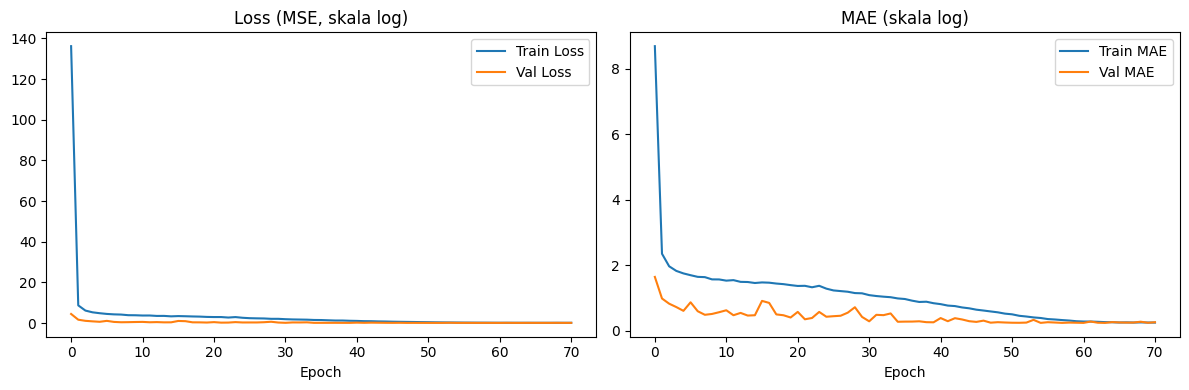

In [12]:
# Visualisasi proses training
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss (MSE, skala log)"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(history.history["mae"], label="Train MAE")
axes[1].plot(history.history["val_mae"], label="Val MAE")
axes[1].set_title("MAE (skala log)"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## Langkah 9: Evaluasi Model pada Data Test


In [13]:
y_pred_log = model.predict(X_test_p).ravel()

# Skala log
print("== Skala log ==")
print("R²  :", round(r2_score(y_test, y_pred_log), 4))

# Skala Rupiah
y_true = np.expm1(y_test)
y_pred = np.expm1(y_pred_log)

mae  = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2   = r2_score(y_true, y_pred)

print("\n== Skala Rupiah ==")
print(f"MAE  : Rp {mae:,.0f}")
print(f"RMSE : Rp {rmse:,.0f}")
print(f"R²   : {r2:.4f}")

48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
== Skala log ==
R²  : 0.7401

== Skala Rupiah ==
MAE  : Rp 1,111,552,628
RMSE : Rp 1,799,229,495
R²   : 0.7950


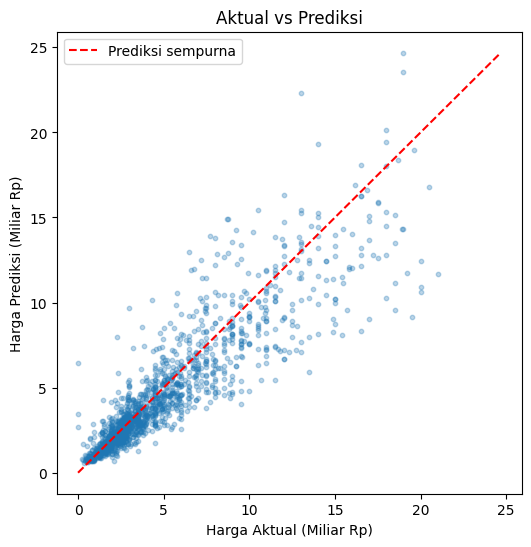

,aktual (Rp),prediksi (Rp),selisih (%)
0,1.550000e+09,1.207428e+09,-22.1
1,5.500000e+09,5.651144e+09,2.7
2,1.850000e+09,2.033475e+09,9.9
3,1.350000e+10,1.025091e+10,-24.1
4,2.850000e+09,2.015324e+09,-29.3
5,9.500000e+09,9.012796e+09,-5.1
6,3.800000e+09,4.654067e+09,22.5
7,3.600000e+09,2.373260e+09,-34.1
8,4.000000e+08,1.025501e+09,156.4
9,1.150000e+10,1.151824e+10,0.2


In [14]:
# Aktual vs Prediksi
plt.figure(figsize=(6, 6))
plt.scatter(y_true / 1e9, y_pred / 1e9, alpha=0.3, s=10)
lim = [0, max(y_true.max(), y_pred.max()) / 1e9]
plt.plot(lim, lim, "r--", label="Prediksi sempurna")
plt.xlabel("Harga Aktual (Miliar Rp)")
plt.ylabel("Harga Prediksi (Miliar Rp)")
plt.title("Aktual vs Prediksi")
plt.legend(); plt.show()

hasil = pd.DataFrame({
    "aktual (Rp)": y_true[:10].round(0),
    "prediksi (Rp)": y_pred[:10].round(0),
})
hasil["selisih (%)"] = ((hasil["prediksi (Rp)"] - hasil["aktual (Rp)"]) / hasil["aktual (Rp)"] * 100).round(1)
hasil

## Langkah 10: Menyimpan Model dan Preprocessor (Artefak Deployment)


In [15]:
# 1. Simpan model
model.save("house_price_model.h5")
model.save("house_price_model.keras")
print("✅ Model berhasil disimpan: house_price_model.h5 & house_price_model.keras")

# 2. Simpan preprocessor (scaler + encoder)
with open("preprocessor.pkl", "wb") as f:
    pickle.dump(preprocessor, f)
print("✅ Preprocessor berhasil disimpan: preprocessor.pkl")

# 3. Simpan metadata untuk aplikasi deployment
city_district = data.groupby("city")["district"].unique().apply(lambda x: sorted(x)).to_dict()
metadata = {
    "num_cols": NUM_COLS,
    "cat_cols": CAT_COLS,
    "target": TARGET,
    "target_transform": "log1p (kembalikan dengan expm1)",
    "city_to_districts": city_district,
    "metrics_test": {"MAE": float(mae), "RMSE": float(rmse), "R2": float(r2)},
}
with open("metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print("✅ Metadata berhasil disimpan: metadata.json")

print("\nFile di folder kerja:", [f for f in os.listdir(".") if f.endswith((".h5", ".keras", ".pkl", ".json"))])

✅ Model berhasil disimpan: house_price_model.h5 & house_price_model.keras
✅ Preprocessor berhasil disimpan: preprocessor.pkl
✅ Metadata berhasil disimpan: metadata.json

File di folder kerja: ['house_price_model.keras', 'metadata.json', 'preprocessor.pkl', 'house_price_model.h5']


## Langkah 11: Uji Load Model & Prediksi (Simulasi Deployment)


In [16]:
loaded_model = tf.keras.models.load_model("house_price_model.h5", compile=False)
with open("preprocessor.pkl", "rb") as f:
    loaded_prep = pickle.load(f)

def predict_price(city, district, bed_rooms, bath_rooms, carport, land_area, building_area):
    row = pd.DataFrame([{
        "bed_rooms": bed_rooms, "bath_rooms": bath_rooms, "carport": carport,
        "land_area": land_area, "building_area": building_area,
        "city": city, "district": district,
    }])
    x = loaded_prep.transform(row).astype("float32")
    pred_log = loaded_model.predict(x, verbose=0).ravel()[0]
    return float(np.expm1(pred_log))

# Contoh: ambil city/district yang pasti ada di data
contoh = data.iloc[0]
harga = predict_price(contoh["city"], contoh["district"], contoh["bed_rooms"], contoh["bath_rooms"],
                      contoh["carport"], contoh["land_area"], contoh["building_area"])
print(f"Rumah di {contoh['district']}, {contoh['city']}")
print(f"Harga aktual   : Rp {contoh['price']:,.0f}")
print(f"Harga prediksi : Rp {harga:,.0f}")

Rumah di Citra Garden, Jakarta Barat
Harga aktual   : Rp 5,900,000,000
Harga prediksi : Rp 5,668,697,600


In [18]:
# (Opsional) Download artefak ke komputer saat memakai Google Colab
try:
    from google.colab import files
    for fn in ["house_price_model.h5", "preprocessor.pkl", "metadata.json"]:
        files.download(fn)
except ImportError:
    print("Bukan di Google Colab – file sudah tersimpan di folder kerja.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>